# Heston 模型下看跌期权关于初始波动率的二阶导数

我们考虑 Heston 模型（忽略相关性 $\rho=0$）：

$$
\begin{aligned}
dX_t &= r X_t dt + \sqrt{Y_t} X_t dW_1 \
dY_t &= \kappa(\theta - Y_t)dt + \xi \sqrt{Y_t} dW_2
\end{aligned}
$$

我们关注固定时刻 $t_0$ 下，看跌期权价格：

$$
v(t_0, x, y) = \mathbb{E}\left[e^{-r(T-t_0)} (K - X_T)^+ \mid X_{t_0}=x, Y_{t_0}=y \right]
$$

目标是数值计算并可视化：

$$
\frac{\partial^2 v}{\partial y^2}(t_0, x, y)
$$

并观察其在 $(x,y)$ 平面上可能“触碰 0” 的现象。


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

# 固定随机种子
np.random.seed(42)

# 模型参数
r = 0.03
kappa = 2.0
theta = 0.5
xi = 0.5

T = 1.0
t0 = 0.0
dt = (T - t0) / 100
N_steps = 100
N_paths = 50000

K = 1.0

# 提前生成布朗运动
Z1 = np.random.randn(N_paths, N_steps)
Z2 = np.random.randn(N_paths, N_steps)

In [2]:
def simulate_payoff(x0, y0):
    X = np.full(N_paths, x0)
    Y = np.full(N_paths, y0)

    for t in range(N_steps):
        dW1 = np.sqrt(dt) * Z1[:, t]
        dW2 = np.sqrt(dt) * Z2[:, t]

        # 保证 Y 非负（简单截断）
        Y = np.maximum(Y, 0)

        X = X + r * X * dt + np.sqrt(Y) * X * dW1
        Y = Y + kappa * (theta - Y) * dt + xi * np.sqrt(Y) * dW2

    payoff = np.maximum(K - X, 0)
    return np.exp(-r * (T - t0)) * np.mean(payoff)

In [3]:
x_vals = np.linspace(0.01, 4.01, 50)
y_vals = np.linspace(0.01, 1.0, 25)

V = np.zeros((len(x_vals), len(y_vals)))

for i, x in enumerate(x_vals):
    for j, y in enumerate(y_vals):
        V[i, j] = simulate_payoff(x, y)

In [4]:
dy = y_vals[1] - y_vals[0]

V_yy = np.zeros_like(V)

for i in range(len(x_vals)):
    for j in range(1, len(y_vals)-1):
        V_yy[i, j] = (V[i, j+1] - 2*V[i, j] + V[i, j-1]) / (dy**2)

V_yy_smooth = gaussian_filter(V_yy, sigma=1)

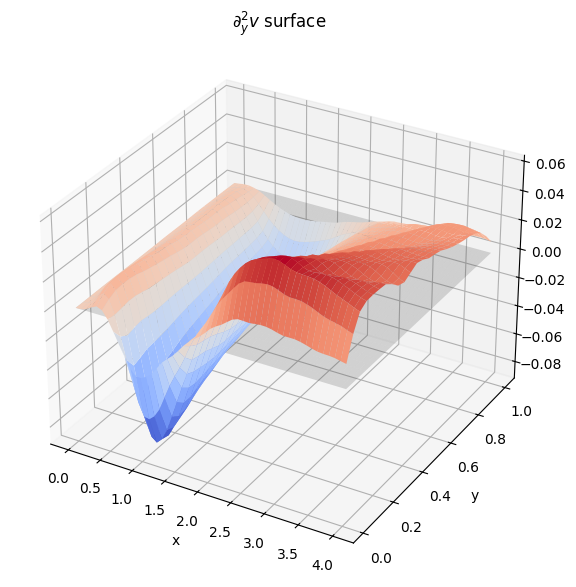

In [5]:
from mpl_toolkits.mplot3d import Axes3D

X_grid, Y_grid = np.meshgrid(x_vals, y_vals, indexing='ij')

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

# 原始曲面
ax.plot_surface(X_grid, Y_grid, V_yy_smooth, cmap='coolwarm')

# z = 0 平面
Z0 = np.zeros_like(X_grid)
ax.plot_surface(X_grid, Y_grid, Z0, alpha=0.2, color='gray')

ax.set_xlabel('x')
ax.set_ylabel('y')
# ax.set_zlabel('$\partial^2_y v$')

plt.title('$\partial^2_y v$ surface')
plt.show()

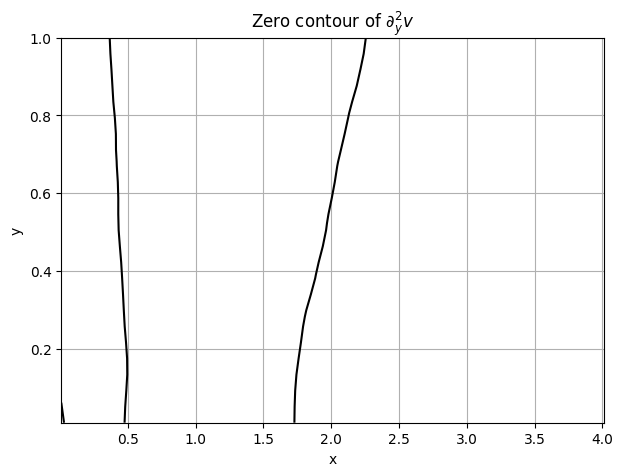

In [6]:
plt.figure(figsize=(7,5))

CS = plt.contour(X_grid, Y_grid, V_yy_smooth, levels=[0], colors='black')

plt.xlabel('x')
plt.ylabel('y')
plt.title('Zero contour of $\partial^2_y v$')

plt.grid(True)
plt.show()